# Nonzero-correlation candidates closest to the previous rank-3 experiment

**Exploratory sensitivity study—not a claim of improved covariance estimation.**
Fix the old rank-3 fits: LS auxiliary, 16-step unpenalized logistic FISTA posterior,
no intercept, Delta2, same data, weights and half/half count prior. Use 1024 draws,
seed123, and recheck shortlisted candidates with 1024 draws/seed42. Posterior
state max100 evaluations, likelihood quadrature160, up to36 parallel jobs.

Construct three covariance directions: the weighted LS coefficient Gram matrix;
the Gram matrix of LS coefficients fitted separately on either side of the
data-estimated pilot split; and the direct moment-fit matrix for old rank3.
All coefficient Grams are B-transpose-B/n, without estimation-noise correction.
They are data-informed but may be biased. No ground-truth split or signal is used.

For each direction, test convex mixtures with the old diagonal rho, either at its
raw scale or rescaled to the same trace as old rho (explicitly separates shape
from magnitude). Trace-matched weights: .01,.03,.06,.1,.2,.35,.5,.75,1.
Raw-scale weights: .001,.003,.01,.03,.06,.1,.2,.5,1. Include the exact old baseline:
**55 total candidates**. These paths inherit the old baseline's estimation
limitations; in particular trace matching is not independent signal-strength
estimation. All matrices and settings are saved.

Rank conditional shape similarity to **rank3**, not to the older original curve.
Require absolute correlation at least .05 for the shortlist, avoiding a vacuous
near-zero perturbation win. No P(1) cutoff. Recheck the top10 and at least two
per covariance family. Report correlation, rho entries, P(1), moment residuals,
and numerical sensitivity. Every candidate is retained, not only favorable ones.
Tuning covariance shrinkage to a desired posterior is outcome-guided exploration,
not calibration, independent validation, or evidence that the covariance is true.


In [1]:
"""Exploratory correlated covariance paths targeting the saved rank-3 curve.

These are declared data-informed shrinkage paths, not newly validated estimators.
"""
from tools.myocardial_final_redo import *

BASE=Path('results/myocardial_final_redo_e3d965cc4b9b')
DIRECT=Path('results/myocardial_direct_moments_fde92cd39485')


def blend_covariance(base,estimate,weight,match_trace):
    if not 0<=weight<=1:raise ValueError('weight outside [0,1]')
    base=np.asarray(base,float);estimate=np.asarray(estimate,float)
    if match_trace:estimate=estimate*np.trace(base)/np.trace(estimate)
    out=(1-weight)*base+weight*estimate
    if np.linalg.eigvalsh(out).min()<=0:raise ValueError('blend is not positive definite')
    return out


def make_candidates(data):
    X,y=data['X'],data['y'];n=len(y)
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in data['phi']])
    weighted=B.T@B/n
    split=data['pilot']
    if not 0<split<n:raise ValueError('segmented Gram requires a non-null estimated pilot')
    segmented=np.column_stack([np.linalg.lstsq(X[:split],y[:split],rcond=None)[0],
                              np.linalg.lstsq(X[split:],y[split:],rcond=None)[0]])
    segmented=segmented.T@segmented/n
    prepared=pickle.load((DIRECT/'old_rank3_fits.pkl').open('rb'))
    direct=pickle.load((DIRECT/'selected_rho_fits.pkl').open('rb'))[prepared['aux_key']]['rho']
    estimates=dict(weighted_LS_Gram=weighted,pilot_segment_LS_Gram=segmented,direct_moment=direct)
    rows=[dict(id='baseline',family='baseline',weight=0.,trace_matched=True,rho=data['rho'])]
    for family,estimate in estimates.items():
        for matched in (True,False):
            weights=(.01,.03,.06,.1,.2,.35,.5,.75,1.) if matched else (.001,.003,.01,.03,.06,.1,.2,.5,1.)
            for w in weights:
                rho=blend_covariance(data['rho'],estimate,w,matched)
                rows.append(dict(id=f'{family}_trace{int(matched)}_w{w:g}',family=family,
                    weight=w,trace_matched=matched,rho=rho))
    return rows,estimates


def evaluate(candidate,data,seed,root):
    path=root/f"{candidate['id']}_seed{seed}.pkl"
    if path.exists():return pickle.load(path.open('rb'))
    folder=root/candidate['id'];folder.mkdir(exist_ok=True)
    local=dict(data,rho=candidate['rho'],root=folder)
    try:
        # One candidate per worker; location checkpoints survive interruption.
        states=[location_task(local,(1.,1.),10,seed,i) for i in range(len(data['eta']))]
        result=normalize_posterior([s['log_likelihood'] for s in states],data['prior'])
        rho=candidate['rho'];X,y,phi=data['X'],data['y'],data['phi'];n,p=X.shape
        B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
        V,_=empirical_adjustment(X@B,y,phi,n/p,loss='squared')
        _,psi=pilot(X@B,y,data['eta'],'squared');S=V.T@V/n
        predicted=squared_logistic_state(rho,phi,psi,n/p)['moment']
        residual=float(np.linalg.norm(predicted-S,'fro'))
        result.update(candidate,seed=seed,ages=data['ages'][data['eta'][1:]],P_1=result['presence'],
            correlation=rho[0,1]/np.sqrt(rho[0,0]*rho[1,1]),rho_11=rho[0,0],rho_12=rho[0,1],rho_22=rho[1,1],
            moment_residual=residual,relative_residual=residual/np.linalg.norm(S,'fro'),
            max_state_residual=max(s['state']['training_residual'] for s in states),checkpoint=str(path))
    except Exception:result=dict(error=traceback.format_exc(),id=candidate['id'],seed=seed)
    atomic_save(path,result);print('Candidate complete:',candidate['id'],seed,flush=True);return result


def scalar_results(results,target):
    rows=[]
    for result in results:
        if 'error' in result:continue
        row={k:v for k,v in result.items() if k not in ('rho','ages','conditional','probabilities','log_likelihood')}
        row.update(TV_to_rank3=.5*np.abs(result['conditional']-target['conditional']).sum(),
            P1_difference=result['P_1']-target['P_1'],peak_age=result['ages'][np.argmax(result['conditional'])],
            mass_above55=result['conditional'][result['ages']>55].sum())
        rows.append(row)
    return pd.DataFrame(rows)


def run(smoke=False):
    data=pickle.load((BASE/'fresh_fit_and_rho.pkl').open('rb'))
    candidates,estimates=make_candidates(data)
    digest=hashlib.sha256(Path('tools/myocardial_correlated_target.py').read_bytes()+(BASE/'specification.json').read_bytes()).hexdigest()[:12]
    root=Path('results')/('myocardial_correlated_rank3_'+digest);root.mkdir(exist_ok=True)
    atomic_save(root/'candidate_specifications.pkl',dict(candidates=candidates,estimates=estimates))
    (root/'specification.json').write_text(json.dumps(dict(target='previous overall rank3, 1024 draws',
        source=str(BASE),candidate_count=len(candidates),draws=1024,primary_seed=123,check_seed=42,
        meaningful_correlation_cutoff=.05,selection='TV to rank3 among abs(correlation)>=.05; no P1 filter',
        warning='Outcome-targeted covariance sensitivity paths, not validated rho estimators'),indent=2))
    if smoke:
        for c in candidates:assert np.linalg.eigvalsh(c['rho']).min()>0
        tiny=dict(data,eta=data['eta'][:2],prior=np.array([.5,.5]))
        c=dict(candidates[2],id='smoke_only')
        r=evaluate(c,tiny,123,root)
        assert 'error' not in r,r
        print('All',len(candidates),'covariances valid; two-location posterior smoke passed.');return root
    # Reuse only the exact baseline at the same integration setting.
    folder=root/'baseline';folder.mkdir(exist_ok=True)
    for i in range(len(data['eta'])):
        src=BASE/f'eig100_100_q10_seed123_location{i}.pkl';dst=folder/src.name
        if not dst.exists():atomic_save(dst,pickle.load(src.open('rb')))
    with parallel_config(backend='loky',inner_max_num_threads=1):
        results=Parallel(n_jobs=36)(delayed(evaluate)(c,data,123,root) for c in candidates)
    target=next(r for r in results if r['id']=='baseline')
    archived=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
    np.testing.assert_allclose(target['conditional'],archived['conditional'],atol=1e-12)
    np.testing.assert_allclose(target['P_1'],archived['presence'],atol=1e-12)
    summary=scalar_results(results,target);summary.to_csv(root/'summary.csv',index=False)
    eligible=summary[summary.correlation.abs()>=.05].sort_values('TV_to_rank3')
    selected=pd.concat([eligible.head(10),eligible.groupby('family',sort=False).head(2)]).drop_duplicates('id')
    selected.to_csv(root/'selected_for_validation.csv',index=False)
    ids=set(selected.id)|{'baseline'}
    with parallel_config(backend='loky',inner_max_num_threads=1):
        checked=Parallel(n_jobs=36)(delayed(evaluate)(c,data,42,root) for c in candidates if c['id'] in ids)
    check_target=next(r for r in checked if r['id']=='baseline')
    validation=scalar_results(checked,check_target);validation.to_csv(root/'validation.csv',index=False)
    ranked=[]
    for row in selected.to_dict('records'):
        check=next(r for r in checked if r['id']==row['id'])
        if 'error' in check:continue
        original=next(r for r in results if r['id']==row['id'])
        check_tv=.5*np.abs(check['conditional']-check_target['conditional']).sum()
        row.update(mean_TV_to_rank3=(row['TV_to_rank3']+check_tv)/2,
            P1_min=min(original['P_1'],check['P_1']),P1_max=max(original['P_1'],check['P_1']),
            numerical_TV=.5*np.abs(original['conditional']-check['conditional']).sum(),check_checkpoint=check['checkpoint'])
        ranked.append(row)
    final=pd.DataFrame(ranked).sort_values('mean_TV_to_rank3');final.insert(0,'rank',np.arange(1,len(final)+1))
    final.to_csv(root/'ranked.csv',index=False)
    errors=[r for r in results+checked if 'error' in r]
    (root/'errors.json').write_text(json.dumps(errors,indent=2))
    print('CORRELATED RANK3 STUDY COMPLETE:',root,'errors:',len(errors),flush=True)
    return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from IPython.display import display,Markdown
root=run()
summary=pd.read_csv(root/'summary.csv');ranked=pd.read_csv(root/'ranked.csv')
print('All candidates:');display(summary)
print('Best candidates with absolute correlation >=0.05:')
display(ranked[['rank','family','trace_matched','weight','rho_11','rho_12','rho_22','correlation',
    'P1_min','P1_max','mean_TV_to_rank3','numerical_TV','relative_residual']].style.format(precision=6))
print('Errors:',json.loads((root/'errors.json').read_text()))


Candidate complete: baseline 123


Candidate complete: pilot_segment_LS_Gram_trace1_w1 123


Candidate complete: pilot_segment_LS_Gram_trace1_w0.1 123


Candidate complete: weighted_LS_Gram_trace1_w1 123


Candidate complete: pilot_segment_LS_Gram_trace1_w0.03 123


Candidate complete: pilot_segment_LS_Gram_trace0_w0.001 123


... (60 outputs left out)

,presence,absence,id,family,weight,trace_matched,seed,P_1,correlation,rho_11,rho_12,rho_22,moment_residual,relative_residual,max_state_residual,checkpoint,TV_to_rank3,P1_difference,peak_age,mass_above55
0,0.482719,5.172810e-01,baseline,baseline,0.000,True,123,0.482719,0.000000,0.003271,0.000000e+00,0.003271,0.013166,0.226815,1.107784e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.000000,0.000000,81.0,9.767437e-01
1,0.481899,5.181008e-01,weighted_LS_Gram_trace1_w0.01,weighted_LS_Gram,0.010,True,123,0.481899,0.009155,0.003267,2.994600e-05,0.003275,0.013168,0.226840,1.113890e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.011828,-0.000820,81.0,9.651400e-01
2,0.485392,5.146085e-01,weighted_LS_Gram_trace1_w0.03,weighted_LS_Gram,0.030,True,123,0.485392,0.027466,0.003259,8.983801e-05,0.003283,0.013171,0.226889,1.126662e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.053771,0.002672,81.0,9.232664e-01
3,0.517764,4.822364e-01,weighted_LS_Gram_trace1_w0.06,weighted_LS_Gram,0.060,True,123,0.517764,0.054933,0.003247,1.796760e-04,0.003294,0.013175,0.226964,1.117948e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.201643,0.035045,30.0,7.751673e-01
4,0.665217,3.347835e-01,weighted_LS_Gram_trace1_w0.1,weighted_LS_Gram,0.100,True,123,0.665217,0.091559,0.003232,2.994600e-04,0.003310,0.013181,0.227063,1.110561e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.582244,0.182497,30.0,3.945008e-01
5,0.985396,1.460390e-02,weighted_LS_Gram_trace1_w0.2,weighted_LS_Gram,0.200,True,123,0.985396,0.183158,0.003193,5.989201e-04,0.003349,0.013195,0.227310,1.135823e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.966716,0.502677,30.0,1.002818e-02
6,0.999964,3.602501e-05,weighted_LS_Gram_trace1_w0.35,weighted_LS_Gram,0.350,True,123,0.999964,0.320717,0.003134,1.048110e-03,0.003408,0.013217,0.227682,1.121790e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.976724,0.517245,30.0,1.971973e-05
7,1.000000,8.598415e-08,weighted_LS_Gram_trace1_w0.5,weighted_LS_Gram,0.500,True,123,1.000000,0.458586,0.003075,1.497300e-03,0.003467,0.013238,0.228053,1.132020e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.976744,0.517281,30.0,3.862116e-08
8,1.000000,3.547516e-12,weighted_LS_Gram_trace1_w0.75,weighted_LS_Gram,0.750,True,123,1.000000,0.689428,0.002977,2.245950e-03,0.003564,0.013274,0.228672,1.113807e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.976744,0.517281,30.0,1.231582e-12
9,1.000000,1.354920e-16,weighted_LS_Gram_trace1_w1,weighted_LS_Gram,1.000,True,123,1.000000,0.922152,0.002880,2.994600e-03,0.003662,0.013310,0.229292,1.119603e-09,results/myocardial_correlated_rank3_04d94f15c3...,0.976744,0.517281,30.0,7.729988e-12


Best candidates with absolute correlation >=0.05:


,rank,family,trace_matched,weight,rho_11,rho_12,rho_22,correlation,P1_min,P1_max,mean_TV_to_rank3,numerical_TV,relative_residual
0,1,weighted_LS_Gram,True,0.060000,0.003247,0.000180,0.003294,0.054933,0.419524,0.517764,0.109393,0.218832,0.226964
1,2,weighted_LS_Gram,False,0.010000,0.003494,0.000266,0.003564,0.075406,0.440773,0.614249,0.213405,0.416284,0.227306
2,3,weighted_LS_Gram,True,0.100000,0.003232,0.000299,0.003310,0.091559,0.413440,0.665217,0.315517,0.566617,0.227063
3,4,weighted_LS_Gram,True,0.200000,0.003193,0.000599,0.003349,0.183158,0.715204,0.985396,0.865993,0.224202,0.227310
4,5,direct_moment,True,0.060000,0.003170,-0.000168,0.003372,-0.051433,0.898290,0.998030,0.941592,0.089341,0.226608
5,6,weighted_LS_Gram,False,0.030000,0.003940,0.000798,0.004149,0.197423,0.936287,0.998508,0.961652,0.050287,0.228288
6,7,direct_moment,False,1.000000,0.000044,-0.000078,0.000138,-0.999416,0.891482,0.947047,0.965338,0.023332,0.223374
7,8,weighted_LS_Gram,True,0.350000,0.003134,0.001048,0.003408,0.320717,0.999146,0.999964,0.987903,0.000759,0.227682
8,9,direct_moment,True,0.100000,0.003103,-0.000280,0.003439,-0.085794,0.999833,0.999998,0.988049,0.000647,0.226470
9,10,weighted_LS_Gram,False,0.060000,0.004610,0.001596,0.005027,0.331640,0.999998,1.000000,0.988118,0.000310,0.229759


Errors: []


### #1: weighted_LS_Gram; weight=0.06; trace matched=True

Correlation=0.0549; relative moment residual=0.227; P(1)=0.4195–0.5178.

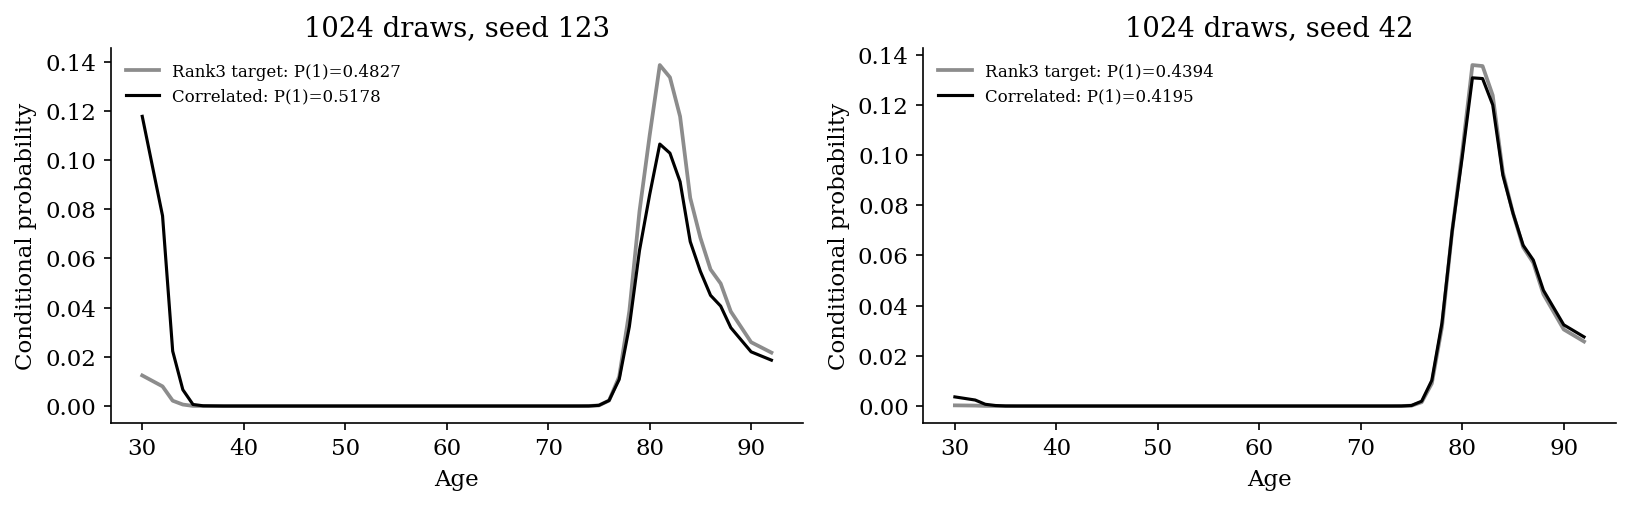

### #2: weighted_LS_Gram; weight=0.01; trace matched=False

Correlation=0.0754; relative moment residual=0.227; P(1)=0.4408–0.6142.

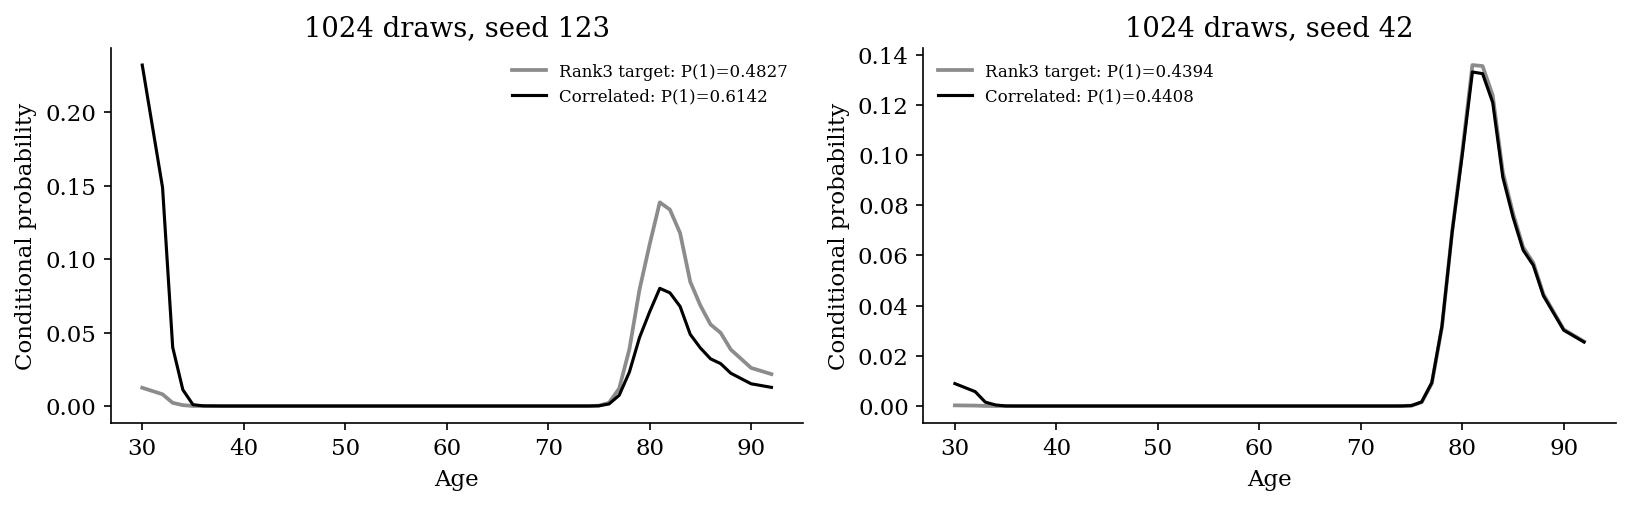

### #3: weighted_LS_Gram; weight=0.1; trace matched=True

Correlation=0.0916; relative moment residual=0.227; P(1)=0.4134–0.6652.

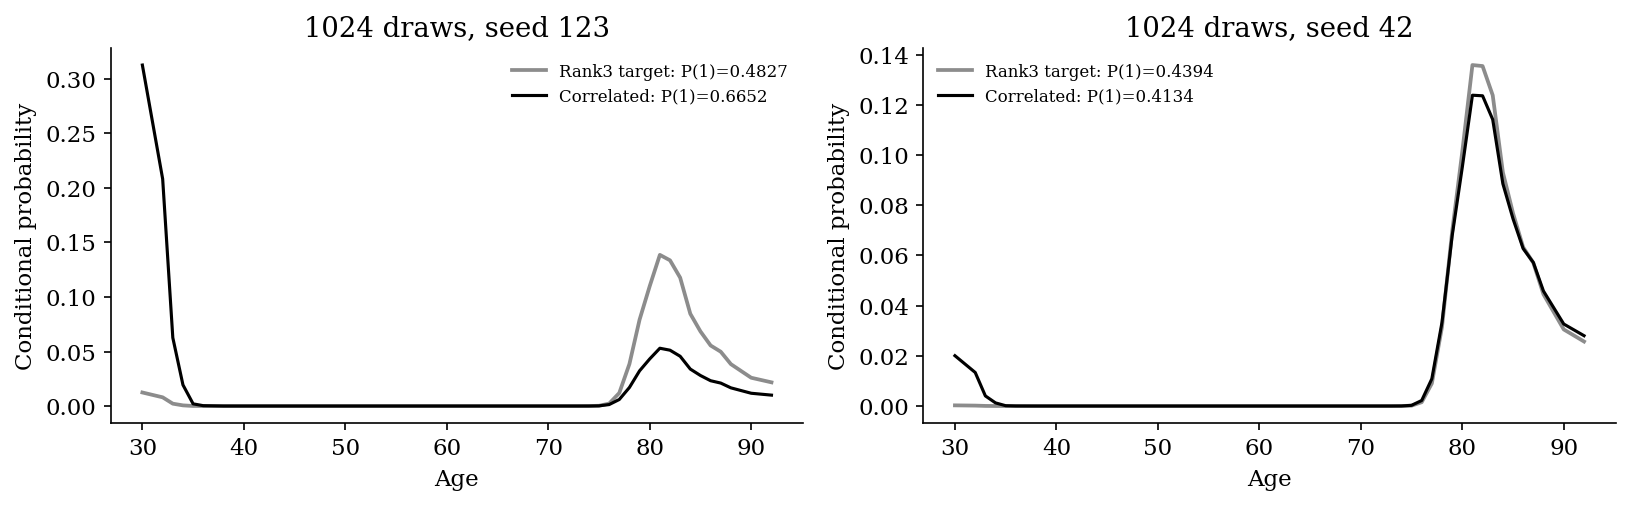

### #4: weighted_LS_Gram; weight=0.2; trace matched=True

Correlation=0.1832; relative moment residual=0.227; P(1)=0.7152–0.9854.

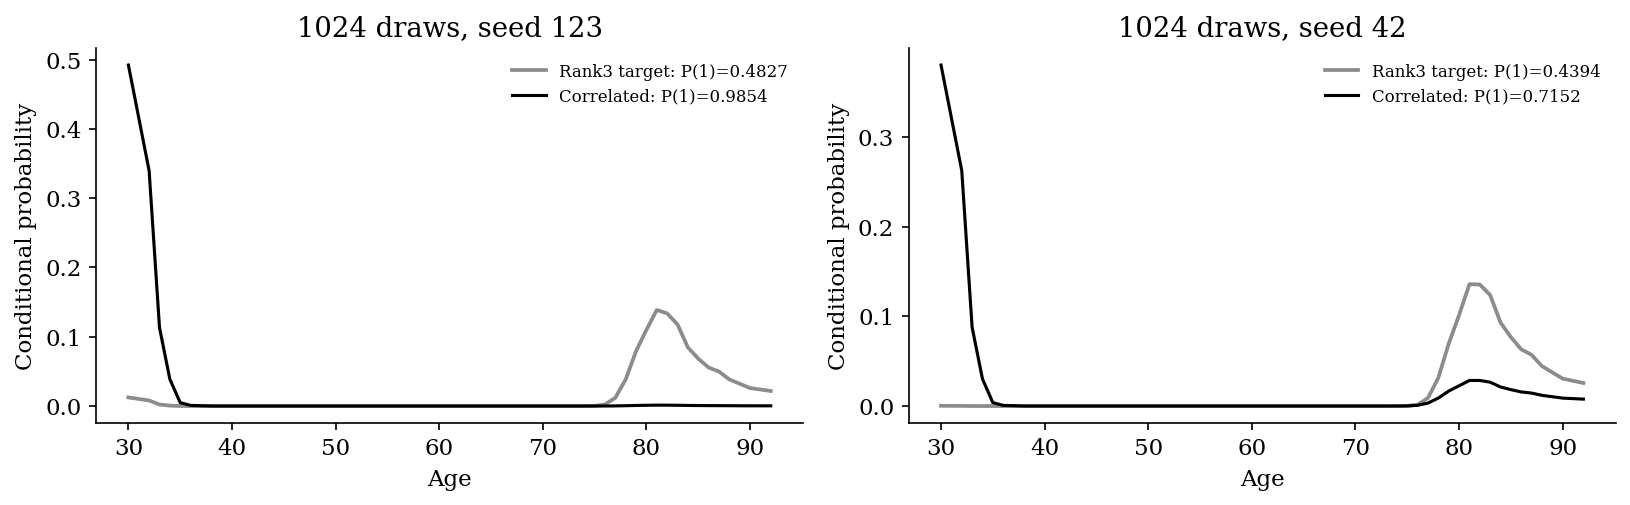

### #5: direct_moment; weight=0.06; trace matched=True

Correlation=-0.0514; relative moment residual=0.227; P(1)=0.8983–0.9980.

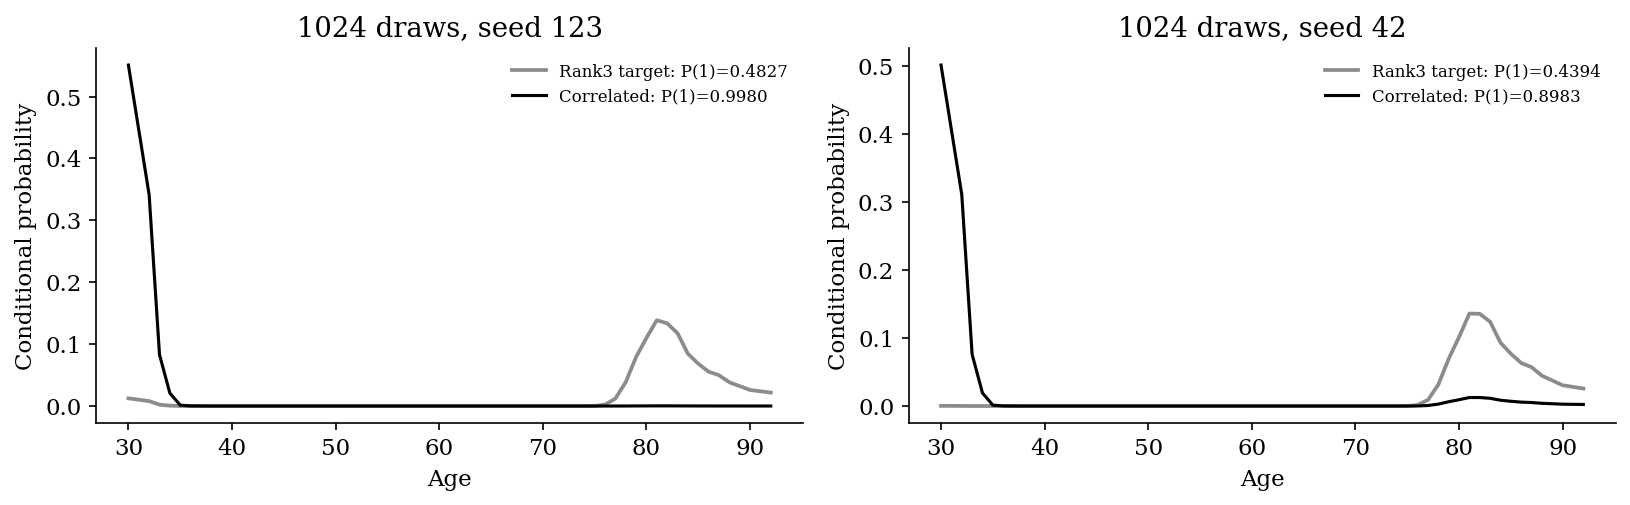

### #6: weighted_LS_Gram; weight=0.03; trace matched=False

Correlation=0.1974; relative moment residual=0.228; P(1)=0.9363–0.9985.

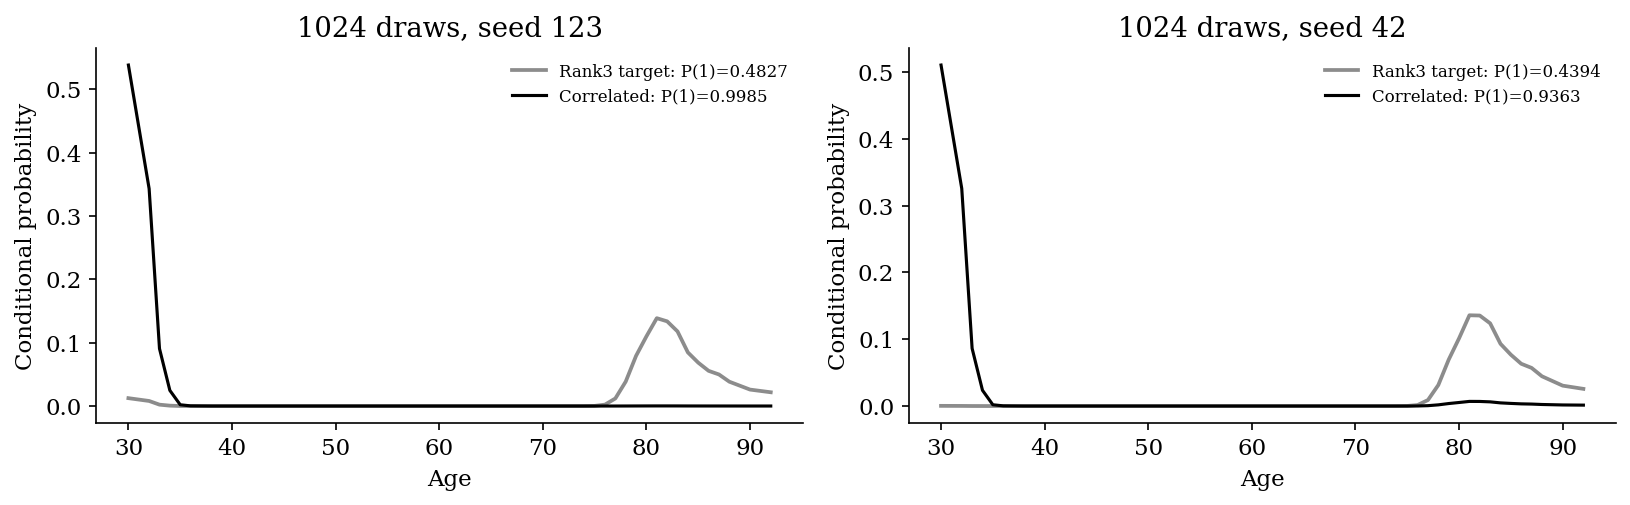

### #7: direct_moment; weight=1; trace matched=False

Correlation=-0.9994; relative moment residual=0.223; P(1)=0.8915–0.9470.

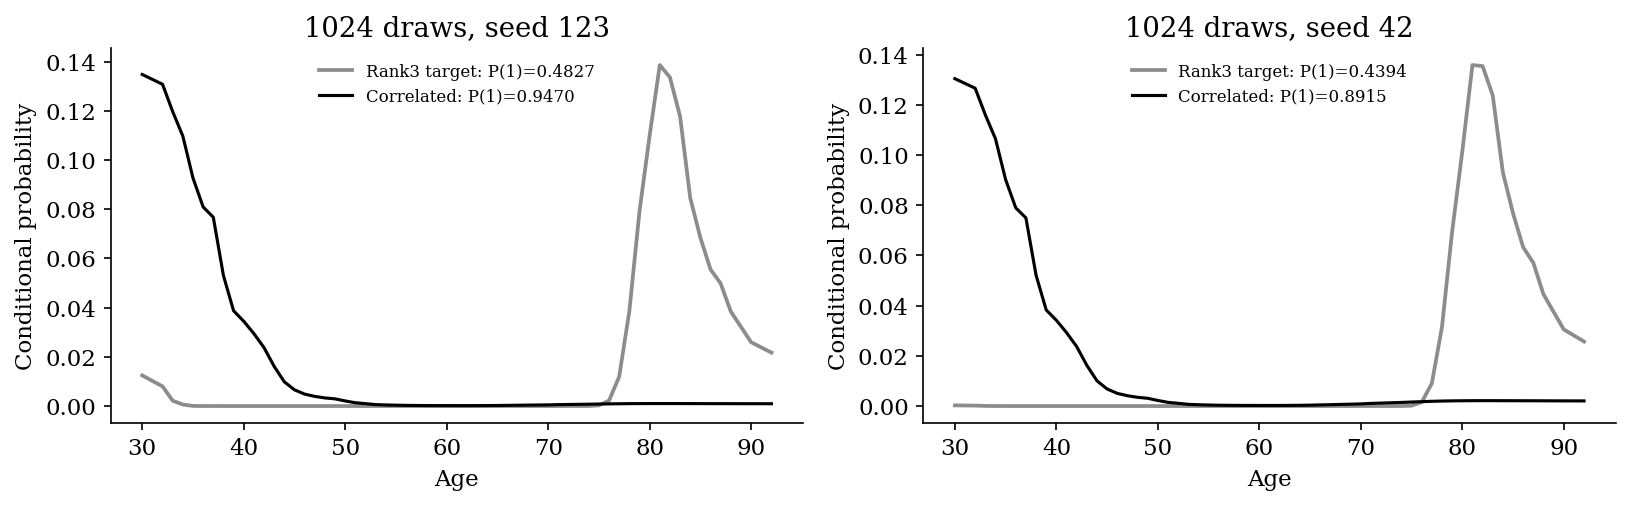

### #8: weighted_LS_Gram; weight=0.35; trace matched=True

Correlation=0.3207; relative moment residual=0.228; P(1)=0.9991–1.0000.

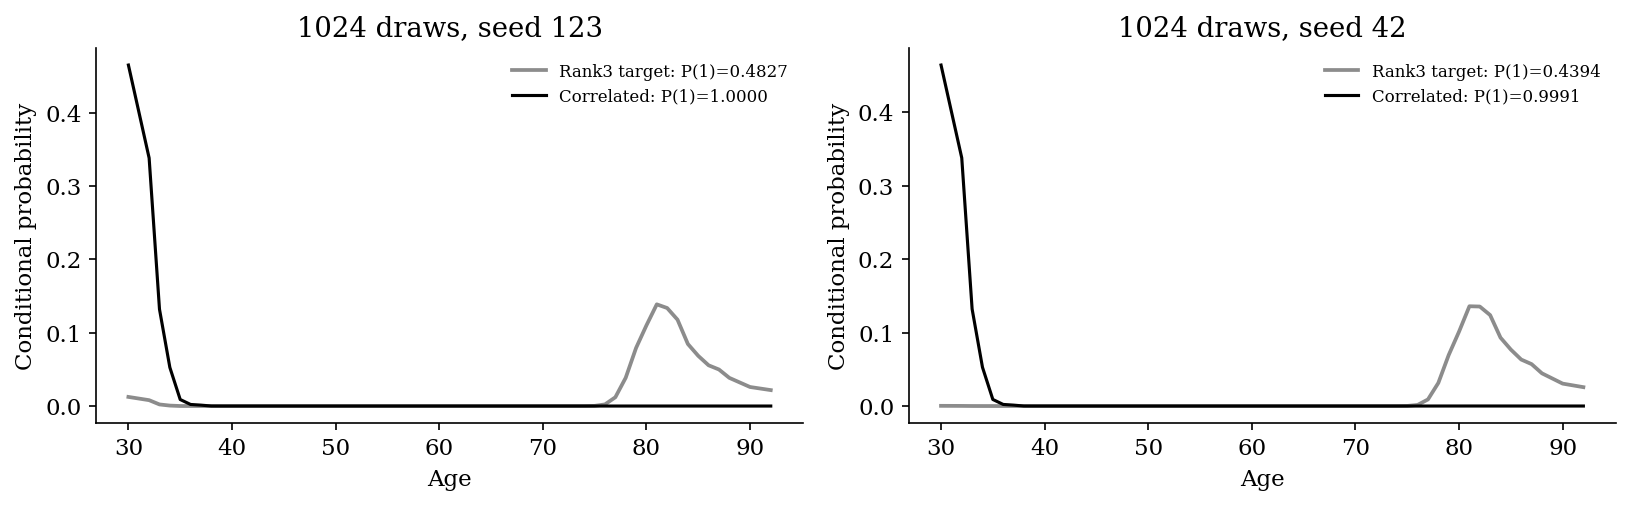

### #9: direct_moment; weight=0.1; trace matched=True

Correlation=-0.0858; relative moment residual=0.226; P(1)=0.9998–1.0000.

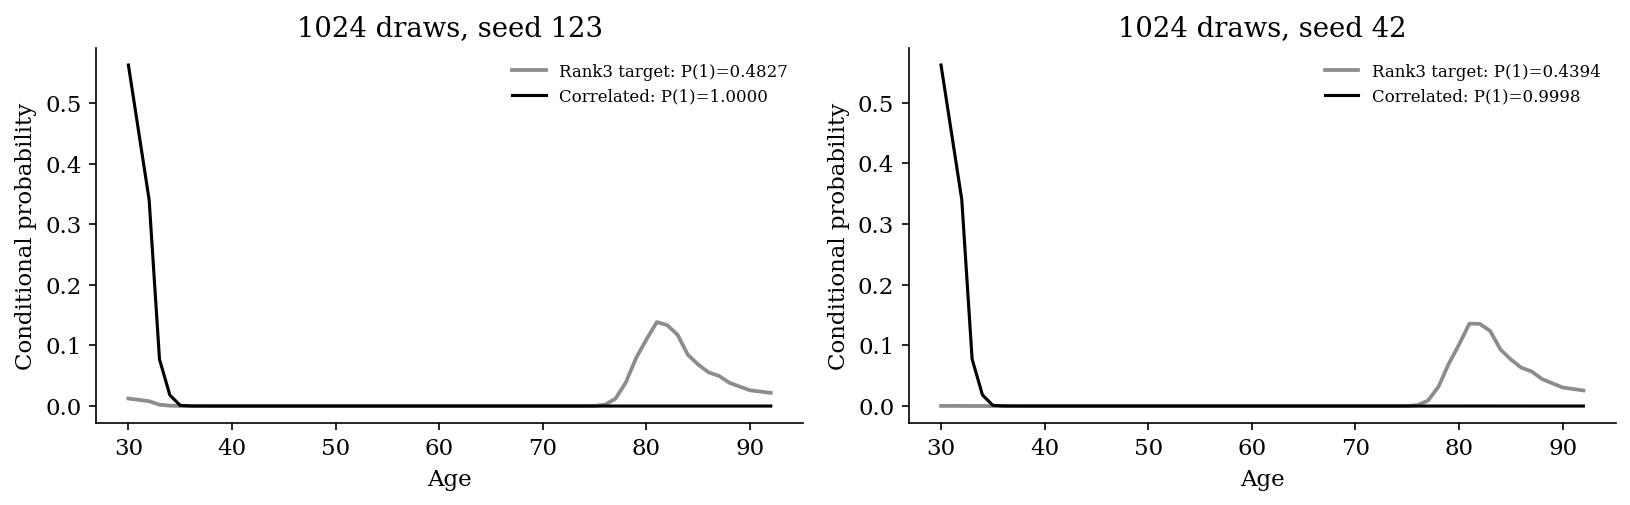

### #10: weighted_LS_Gram; weight=0.06; trace matched=False

Correlation=0.3316; relative moment residual=0.230; P(1)=1.0000–1.0000.

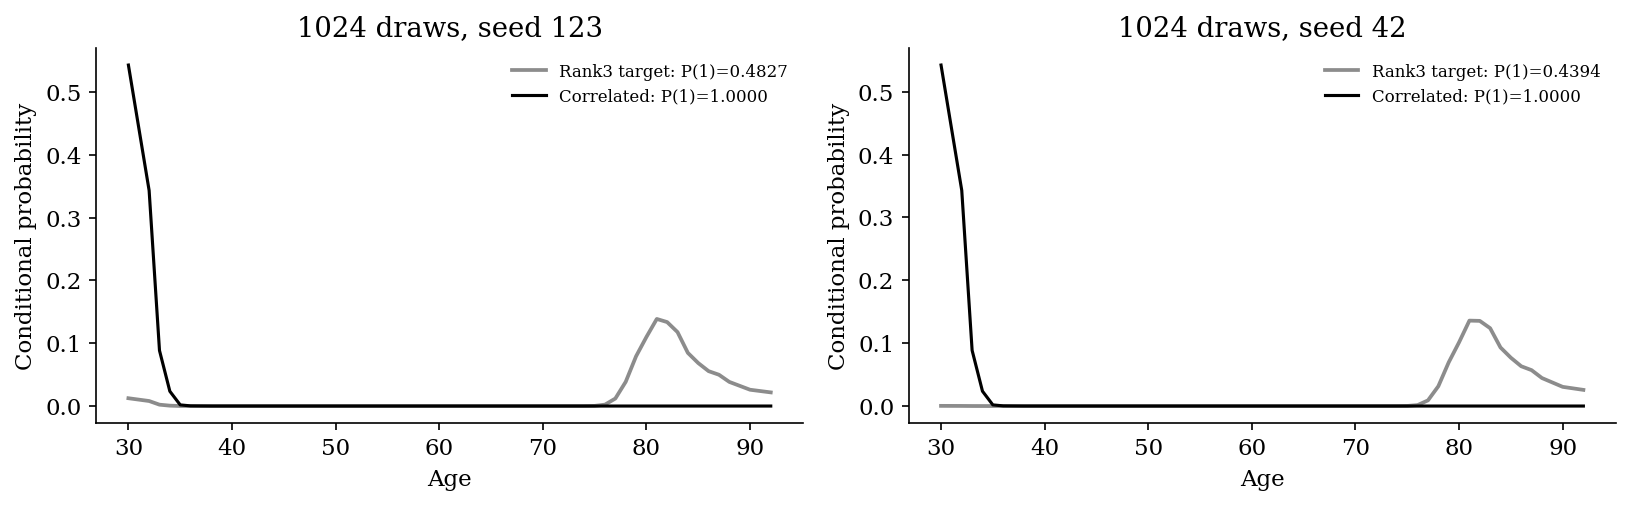

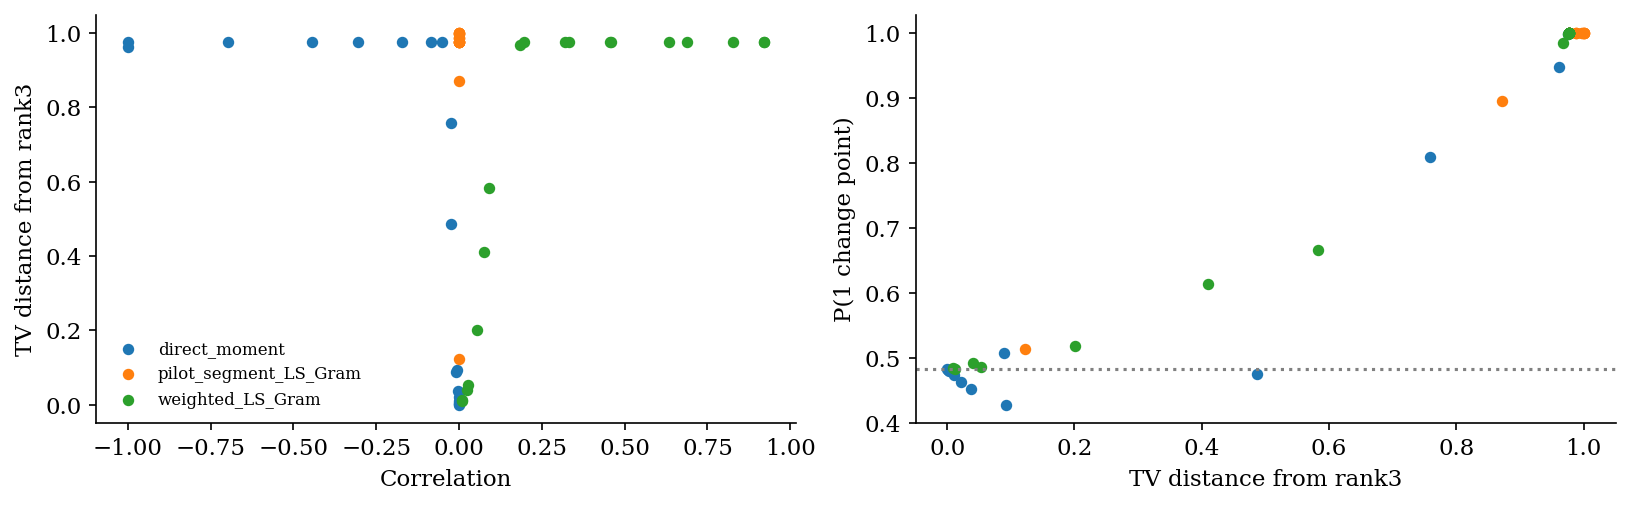

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
targets={seed:pickle.load((root/f'baseline_seed{seed}.pkl').open('rb')) for seed in (123,42)}
for row in ranked.head(10).itertuples():
    first=pickle.load(open(row.checkpoint,'rb'));second=pickle.load(open(row.check_checkpoint,'rb'))
    display(Markdown(f'### #{row.rank}: {row.family}; weight={row.weight:g}; trace matched={row.trace_matched}\n\n'
        f'Correlation={row.correlation:.4f}; relative moment residual={row.relative_residual:.3f}; '
        f'P(1)={row.P1_min:.4f}–{row.P1_max:.4f}.'))
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for ax,seed,r in zip(axes,(123,42),(first,second)):
        t=targets[seed]
        ax.plot(t['ages'],t['conditional'],color='.55',lw=1.8,label=f'Rank3 target: P(1)={t["P_1"]:.4f}')
        ax.plot(r['ages'],r['conditional'],color='black',lw=1.5,label=f'Correlated: P(1)={r["P_1"]:.4f}')
        ax.set(xlabel='Age',ylabel='Conditional probability',title=f'1024 draws, seed {seed}')
        ax.legend(frameon=False,fontsize=8)
    fig.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for family,g in summary[summary.family!='baseline'].groupby('family'):
    axes[0].scatter(g.correlation,g.TV_to_rank3,s=20,label=family)
    axes[1].scatter(g.TV_to_rank3,g.P_1,s=20,label=family)
axes[0].set(xlabel='Correlation',ylabel='TV distance from rank3')
axes[1].set(xlabel='TV distance from rank3',ylabel='P(1 change point)')
axes[1].axhline(targets[123]['P_1'],color='.5',ls=':')
axes[0].legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
